# Student Marks Analyzer (NumPy)

**Goal:** Analyze the marks of 100 students across 5 subjects using vectorized NumPy (no Python loops over the data itself).

> The data is **synthetic** (generated from a normal distribution with a fixed seed), so the findings describe this practice dataset, not real students.

**Structure of this notebook**
0. Setup
1. Stage 1: Create the dataset
2. Mini experiments (`astype`, rounding, clipping order)
3. Stage 2: Basic statistics
4. Stage 3: Finding students (topper, top 5, failures, high scorers)
5. Stage 4: Broadcasting (z-scores, grace marks)
6. Stage 5: Percentile ranks and grades
7. Stage 6: Visualization
8. Key findings and summary of learnings

> Tip: Run `Kernel -> Restart & Run All` before every commit. If it fails, the notebook is broken.

## 0. Setup

In [202]:
import numpy as np

SEED = 42                      # fixed seed -> same data on every run (reproducible results)
N_STUDENTS = 100
SUBJECTS = ["Maths", "Physics", "Chemistry", "English", "CS"]

## Stage 1: Create the dataset

**Why a normal distribution?** Real marks cluster around an average, so a bell curve looks more realistic than uniform random numbers.

- `loc` = the **mean** (center of the bell curve), here 65
- `scale` = the **standard deviation** (how far values typically spread from the mean), here 12
- `size=(100, 5)` = 100 rows (students), 5 columns (subjects)

**Pipeline:** generate (floats) -> `clip` to 0-100 -> `round` -> `astype(int)`

In [203]:
rng = np.random.default_rng(seed=SEED)          # modern way (instead of np.random.seed)
raw = rng.normal(loc=65, scale=12, size=(N_STUDENTS, len(SUBJECTS)))

print("Raw   -> shape:", raw.shape, "| dtype:", raw.dtype, "| ndim:", raw.ndim)
print("Raw   -> min:", raw.min().round(2), "| max:", raw.max().round(2))

Raw   -> shape: (100, 5) | dtype: float64 | ndim: 2
Raw   -> min: 34.2 | max: 99.97


In [204]:
marks = np.clip(raw, 0, 100)     # not in-place: `raw` stays untouched, so re-running cells is safe
marks = np.round(marks)
marks = marks.astype(int)

print("Final -> shape:", marks.shape, "| dtype:", marks.dtype)
print("Final -> min:", marks.min(), "| max:", marks.max(), "| mean:", marks.mean().round(2))
print(marks[:5])

Final -> shape: (100, 5) | dtype: int64
Final -> min: 34 | max: 100 | mean: 64.85
[[69 53 74 76 42]
 [49 67 61 65 55]
 [76 74 66 79 71]
 [55 69 53 76 64]
 [63 57 80 63 60]]


**Sanity check:** shape is `(100, 5)`, dtype is an integer type, and all values are inside 0-100. The mean is close to 65 but not exactly 65, because we only drew 500 random values (sampling randomness).

**Why not `np.clip(..., out=marks)`?** It overwrites the array in place. In a notebook, if you re-run cells out of order you can no longer get the original data back, which causes confusing bugs. Creating a new variable is safer.

## Mini experiments: what I learned

### Experiment 1: what does `astype(int)` do to decimals?

In [205]:
vals = np.array([70.99, 64.9, -0.4, -1.7])
print(vals.astype(int))

[70 64  0 -1]


**Finding:** `astype(int)` **truncates toward zero**. It does not round. `70.99 -> 70` and `-1.7 -> -1` (not -2). That is why we call `np.round` **before** `astype(int)`.

### Experiment 2: does the order of clip / round / int matter?

Test array on purpose includes values just outside the bounds and a `.5` value.

In [206]:
test = np.array([-0.4, 100.4, 99.6, 50.5])

def order_a(x, lo, hi):          # clip -> round -> int
    return np.clip(x, lo, hi).round().astype(int)

def order_b(x, lo, hi):          # round -> int -> clip
    return np.clip(x.round().astype(int), lo, hi)

# Case 1: whole-number bounds (0 and 100)
a1, b1 = order_a(test, 0, 100), order_b(test, 0, 100)
print("Bounds 0, 100    ->", a1, b1, "| equal:", np.array_equal(a1, b1))

# Case 2: fractional bounds (0.5 and 99.5)
a2, b2 = order_a(test, 0.5, 99.5), order_b(test, 0.5, 99.5)
print("Bounds 0.5, 99.5 ->", a2, b2, "| equal:", np.array_equal(a2, b2))
print("dtype A:", a2.dtype, "| dtype B:", b2.dtype)

Bounds 0, 100    -> [  0 100 100  50] [  0 100 100  50] | equal: True
Bounds 0.5, 99.5 -> [  0 100 100  50] [ 0.5 99.5 99.5 50. ] | equal: False
dtype A: int64 | dtype B: float64


**Explanation:**
- With **whole-number bounds** (0 and 100) both orders give the same result. Rounding can never push a value across a whole-number boundary, so the order doesn't matter. That's why I saw no difference on my data.
- With **fractional bounds**, clipping *after* rounding puts decimals like `0.5` back into the array, so the result is no longer integer. Clip-then-round keeps the final result whole numbers.
- **Habit I'll keep:** clip first, then round, then convert. It is correct for any bounds, not just the lucky ones.

### Experiment 3: `np.round` and the `.5` case (round half to even)

In [207]:
halves = np.array([0.5, 1.5, 2.5, 3.5, 50.5, 99.5])
print(halves, "->", np.round(halves))

[ 0.5  1.5  2.5  3.5 50.5 99.5] -> [  0.   2.   2.   4.  50. 100.]


**Finding:** NumPy uses **round half to even** ("banker's rounding"): exactly-`.5` values go to the nearest **even** number. So `0.5 -> 0`, `1.5 -> 2`, `2.5 -> 2`, `50.5 -> 50`. School-style rounding would give `1, 2, 3, 51`. This reduces bias when rounding many values. It rarely matters for random decimals (exact `.5` is very unlikely), but it is good to know.

## Stage 2: Basic statistics

### The `axis` rule
- `axis=0` -> collapse **rows**, get one value **per column** (per subject)
- `axis=1` -> collapse **columns**, get one value **per row** (per student)

Verify on a tiny array where I can check by hand:

In [208]:
tiny = np.array([[1, 2],
                 [3, 4],
                 [5, 6]])          # shape (3, 2)

# Predictions BEFORE running:
# axis=0 -> one value per column  -> shape (2,) -> [3., 4.]
# axis=1 -> one value per row     -> shape (3,) -> [1.5, 3.5, 5.5]
print("axis=0:", tiny.mean(axis=0), tiny.mean(axis=0).shape)
print("axis=1:", tiny.mean(axis=1), tiny.mean(axis=1).shape)

axis=0: [3. 4.] (2,)
axis=1: [1.5 3.5 5.5] (3,)


The output **length** equals the size of the axis that was *kept*: 2 columns -> 2 values, 3 rows -> 3 values.

### 2.1 Average marks per subject and per student

In [209]:
avg_by_subject = marks.mean(axis=0)
avg_by_student = marks.mean(axis=1)

print("Shapes:", avg_by_subject.shape, avg_by_student.shape)   # expect (5,) and (100,)

print("\nAverage per subject:")
for subject, avg in zip(SUBJECTS, avg_by_subject):
    print(f"  {subject:<10} {avg:.2f}")

print("\nFirst 5 students:", avg_by_student[:5].round(2))

Shapes: (5,) (100,)

Average per subject:
  Maths      64.62
  Physics    64.77
  Chemistry  65.28
  English    65.06
  CS         64.51

First 5 students: [62.8 59.4 73.2 63.4 64.6]


### 2.2 Highest and lowest score in each subject

In [210]:
max_by_subject = marks.max(axis=0)
min_by_subject = marks.min(axis=0)

print(f"{'Subject':<10} {'max':>4} {'min':>4}")
for subject, hi, lo in zip(SUBJECTS, max_by_subject, min_by_subject):
    print(f"{subject:<10} {hi:>4} {lo:>4}")

Subject     max  min
Maths        93   37
Physics      95   37
Chemistry    91   39
English     100   34
CS          100   40


### 2.3 Median and standard deviation

Without `axis`, NumPy treats the array as **one flat list of all 500 values**. That gives one overall number, which is useful, but it can't tell me which *subject* is most consistent. For that I need `axis=0`.

In [211]:
print("Overall median:", np.median(marks))
print("Overall std   :", marks.std().round(2))

std_by_subject = marks.std(axis=0)
print("\nStd per subject:")
for subject, s in zip(SUBJECTS, std_by_subject):
    print(f"  {subject:<10} {s:.2f}")

Overall median: 65.0
Overall std   : 11.53

Std per subject:
  Maths      11.31
  Physics    10.43
  Chemistry  11.42
  English    12.63
  CS         11.72


**Why isn't the std exactly 12?** I asked for `scale=12`, but:
1. I only drew 500 random values, so the sample std differs slightly from the true one.
2. Clipping and rounding change the values a little.
3. `np.std` uses `ddof=0` (population formula) by default. For a sample estimate you can pass `ddof=1`.

**Rounding rule I follow:** keep 2 decimals for display (`.2f`). Rounding to a whole number throws away useful information.

### 2.4 Gotcha: a `zip` object can only be used once

In [212]:
pairs = zip(SUBJECTS, avg_by_subject)

print("First loop :", [name for name, _ in pairs])
print("Second loop:", [name for name, _ in pairs])   # empty!

First loop : ['Maths', 'Physics', 'Chemistry', 'English', 'CS']
Second loop: []


**Why:** `zip` returns an **iterator**. Once consumed, it is exhausted. 

**Fixes:** create the `zip` right where you use it (as I did above), or wrap it in `list(zip(...))` if you need to reuse it.

### 2.5 Finding in plain English (numbers pulled from the data, not typed by hand)

In [213]:
best = avg_by_subject.argmax()
worst = avg_by_subject.argmin()
most_spread = std_by_subject.argmax()
most_consistent = std_by_subject.argmin()

print(f"{SUBJECTS[best]} has the highest average ({avg_by_subject[best]:.2f}) and "
      f"{SUBJECTS[worst]} the lowest ({avg_by_subject[worst]:.2f}).")
print(f"{SUBJECTS[most_spread]} varies the most (std {std_by_subject[most_spread]:.2f}), "
      f"while {SUBJECTS[most_consistent]} is the most consistent (std {std_by_subject[most_consistent]:.2f}).")

Chemistry has the highest average (65.28) and CS the lowest (64.51).
English varies the most (std 12.63), while Physics is the most consistent (std 10.43).


**Findings :**
- Chemistry has the highest average (65.28) and CS the lowest (64.51).
- English varies the most (std 12.63), while Physics is the most consistent (std 10.43).

## Stage 3: Finding students

Write your **prediction first** (shape, and *value or index?*), then code, then compare.

| Task | Expected output | Value or index? | Hint |
|---|---|---|---|
| Topper | one number + total | index and value | total per student (which axis?), then `np.argmax` |
| Top 5 students | 5 numbers | **indices** | `np.argsort` is ascending: slice from the end or reverse |
| Failed at least one subject (pass = 35) | list of student indices + count | indices | `marks < 35` is `(100, 5)` bool; `.any(axis=?)`; `np.flatnonzero` |
| Students scoring above 90 in any subject | a count | count | same pattern, with `THRESHOLD = 90` as a variable |

In [214]:
# Practice the argsort idea on a tiny array first:
small = np.array([30, 90, 10, 70])
# Prediction: ...
print(np.argsort(small))
small[np.argsort(small)]



print(small[small > 50])
small[small > 50].sum()

[2 0 3 1]
[90 70]


np.int64(160)

##### 3.1 Compute each student's total marks. Which axis? What should the shape be?
- ``axis``  - 1
- ``shape`` - (100,)

In [215]:
# --- Your Stage 3 code below ---
total_by_student = marks.sum(axis=1)
print(total_by_student.shape)
print(total_by_student[:5])

# Task 1: Topper
topper = np.argmax(total_by_student)
print("Topper student index :",topper+1)
print("Marks :" , total_by_student[topper])

(100,)
[314 297 366 317 323]
Topper student index : 28
Marks : 386


#### **Task 2: Top 5 students**

Get the indices of the top 5 students by total marks, best first.

Print each with their total, like Rank 1: Student 37 -> 392.

In [216]:
top_5 = np.argsort(total_by_student)[:-6:-1]

for rank in range(5):
    print(f"Rank {rank+1}: Student {top_5[rank]+1} -> {total_by_student[top_5[rank]]}.")

Rank 1: Student 28 -> 386.
Rank 2: Student 63 -> 380.
Rank 3: Student 65 -> 377.
Rank 4: Student 91 -> 376.
Rank 5: Student 84 -> 371.


**Ties matter for rankings.** `np.argsort` breaks ties by position in the array, which is arbitrary. Let me check how many ties exist and whether they touch my top 5.

In [217]:
n_repeats = N_STUDENTS - len(np.unique(total_by_student))
print("Totals that repeat an earlier student's total:", n_repeats)
print("Top-5 totals:", total_by_student[top_5])
print("All five distinct (so ties don't affect this top 5):", len(np.unique(total_by_student[top_5])) == 5)

Totals that repeat an earlier student's total: 37
Top-5 totals: [386 380 377 376 371]
All five distinct (so ties don't affect this top 5): True


Many totals repeat, but the top-5 totals are all different, so the ranking here is safe. In a real ranking I would define a tie-break rule explicitly (for example, higher Maths marks first) instead of relying on array position.

#### **Task 3: Students who failed at least one subject (pass mark 35)**
- Create PASS_MARK = 35 as a variable.
- Build a boolean array of failures. Predict its shape.
shape(100,5)
- Collapse it to one True/False per student. Which method, and which axis?
- Report: how many students failed, and their student numbers.

In [218]:
PASS_MARK = 35
fail_mask = marks < PASS_MARK            # (100, 5): True where a single mark is a fail
print("fail_mask shape:", fail_mask.shape)

flags = fail_mask.any(axis=1)            # (100,): one True/False per student
print("flags shape    :", flags.shape)

n_failed = flags.sum()
failed_students = np.flatnonzero(flags) + 1      # +1 -> student numbers start at 1
print(f"Students who failed at least one subject: {n_failed}")
print("Student numbers:", failed_students)

fail_mask shape: (100, 5)
flags shape    : (100,)
Students who failed at least one subject: 1
Student numbers: [59]


**Bug I fixed here:** my earlier loop was `for index in indices: print(indices[index] + 1)`. The loop variable `index` is already a *value* from `indices` (a student position such as 58), so `indices[58]` raises an `IndexError` when `indices` has only one element. When you loop directly over an array, the variable holds the **values**, not the positions. Printing `indices + 1` in one line avoids the loop completely.

**Rule I chose:** a mark of exactly 35 is a pass, so a fail is `< 35`.

In [219]:
# Second route: "passed every subject", then invert with ~
passed_all = (marks >= PASS_MARK).all(axis=1)
print("Both routes agree:", np.array_equal(flags, ~passed_all))

# Does the boundary rule (< vs <=) change today's answer?
print("Marks equal to exactly 35 :", (marks == PASS_MARK).sum())
print("Count with <  35:", (marks <  PASS_MARK).any(axis=1).sum())
print("Count with <= 35:", (marks <= PASS_MARK).any(axis=1).sum())

# Which subject? argwhere returns (student_index, subject_index) pairs
pairs = np.argwhere(fail_mask)
print("pairs shape:", pairs.shape)
for student_idx, subject_idx in pairs:
    print(f"Student {student_idx + 1} failed {SUBJECTS[subject_idx]} with {marks[student_idx, subject_idx]}")

Both routes agree: True
Marks equal to exactly 35 : 0
Count with <  35: 1
Count with <= 35: 1
pairs shape: (1, 2)
Student 59 failed English with 34


Both routes agree, and the count is the same with `<` and `<=`, so the boundary rule doesn't change today's answer (it still matters for other data). The result is consistent with my Stage 2 table: English had a minimum of 34, which is below 35.

Task 4: Scoring above 90

Use a variable: HIGH_SCORE = 90.

Count students who scored above 90 in at least one subject.

Separately, count the total number of scores above 90 (individual cells).

Think about: why can these two numbers differ? Write the reason in a markdown cell. (One student can score above 90 in several subjects.)

In [220]:
HIGH_SCORE = 90
high_mask = marks > HIGH_SCORE                       # strictly above 90, shape (100, 5)
print("high_mask shape:", high_mask.shape)

n_students_high = high_mask.any(axis=1).sum()        # students with at least one high score
n_scores_high = high_mask.sum()                      # every True in the whole 2D mask

print("Students with at least one score above", HIGH_SCORE, ":", n_students_high)
print("Total individual scores above", HIGH_SCORE, "       :", n_scores_high)

high_mask shape: (100, 5)
Students with at least one score above 90 : 8
Total individual scores above 90        : 8


In [221]:
# Cross-checks
per_student = high_mask.sum(axis=1)
print("Students with count > 0 (should match):", (per_student > 0).sum())
print("Most high scores by a single student  :", per_student.max())

per_subject = high_mask.sum(axis=0)
print("\nHigh scores per subject:")
for subject, n in zip(SUBJECTS, per_subject):
    print(f"  {subject:<10} {n}")
print("Subject with most high scores:", SUBJECTS[per_subject.argmax()])

# Boundary effect: ">= 90" instead of "> 90"
print("\nWith >= 90 -> students:", (marks >= HIGH_SCORE).any(axis=1).sum(),
      "| scores:", (marks >= HIGH_SCORE).sum())

Students with count > 0 (should match): 8
Most high scores by a single student  : 1

High scores per subject:
  Maths      2
  Physics    1
  Chemistry  1
  English    1
  CS         3
Subject with most high scores: CS

With >= 90 -> students: 10 | scores: 10


**Why can the two numbers differ?** Counting *students* asks "does this row contain at least one True?" (`any(axis=1)`), while counting *scores* counts every True cell (`sum()` with no axis). If one student scores above 90 in two subjects, they add 1 to the first count and 2 to the second. Here both are 8 because no student scored above 90 in more than one subject (the maximum per student printed above is 1).

**A mistake worth remembering:** `high_mask.any(axis=0).sum()` counts **subjects** that have at least one high score. It can never exceed 5, so it answers a different question.

**Boundary:** "above 90" means `> 90`. Using `>= 90` changes the answer, which shows that the exact rule must be chosen deliberately.

### Task 5 (bonus): combining ideas

In [222]:
# 1. Subject toppers: argmax down each column (axis=0)
top_idx_by_subject = marks.argmax(axis=0)
for col, (subject, idx) in enumerate(zip(SUBJECTS, top_idx_by_subject)):
    print(f"{subject:<10} topper: Student {idx + 1} ({marks[idx, col]})")

# 2. Above the class average in EVERY subject
#    (100, 5) compared with (5,) -> broadcasting, explained in Stage 4
above_all = (marks > marks.mean(axis=0)).all(axis=1)
print("\nStudents above the subject average in all 5 subjects:", above_all.sum())

# 3. Biggest gap between a student's best and worst subject
gap = marks.max(axis=1) - marks.min(axis=1)
g = gap.argmax()
print(f"Biggest gap: Student {g + 1}, gap {gap[g]}, marks {marks[g]}")

Maths      topper: Student 76 (93)
Physics    topper: Student 46 (95)
Chemistry  topper: Student 33 (91)
English    topper: Student 50 (100)
CS         topper: Student 28 (100)

Students above the subject average in all 5 subjects: 5
Biggest gap: Student 76, gap 52, marks [93 63 41 84 60]


## Stage 4: Broadcasting

**Broadcasting rule (in my own words):** NumPy lines up the shapes **from the right**. Two dimensions are compatible if they are equal or if one of them is 1. A dimension of size 1 (or a missing one) is stretched to match the other without copying data.

`marks` is `(100, 5)` and a per-subject statistic is `(5,)`. Aligned from the right: `5` matches `5`, and the missing first dimension is stretched across all 100 rows. So subtracting the per-subject mean from every row works with no loop.

In [223]:
print("marks shape        :", marks.shape)
print("avg_by_subject     :", avg_by_subject.shape)
print("Subtraction shape  :", (marks - avg_by_subject).shape)

marks shape        : (100, 5)
avg_by_subject     : (5,)
Subtraction shape  : (100, 5)


### 4.1 Why `keepdims=True` exists

The same trick fails for a **per-student** statistic, because `(100,)` lined up from the right is `100` vs `5`.

In [224]:
try:
    marks - marks.mean(axis=1)                      # (100, 5) - (100,)
except ValueError as e:
    print("ValueError:", e)

student_mean = marks.mean(axis=1, keepdims=True)    # (100, 1): the 1 can stretch across 5 columns
print("\nWith keepdims=True:", student_mean.shape)

centered = marks - student_mean                     # (100, 5) - (100, 1) works
print("Each student's centered marks sum to ~0:", np.allclose(centered.sum(axis=1), 0))

ValueError: operands could not be broadcast together with shapes (100,5) (100,) 

With keepdims=True: (100, 1)
Each student's centered marks sum to ~0: True


### 4.2 Normalize each subject (z-scores) without loops

`z = (marks - subject_mean) / subject_std`. A z-score says "how many standard deviations above or below the subject average". Positive means above average.

In [225]:
subject_mean = marks.mean(axis=0)     # (5,)
subject_std = marks.std(axis=0)       # (5,)
z = (marks - subject_mean) / subject_std

print("z shape:", z.shape)
print("Each subject mean ~ 0:", np.allclose(z.mean(axis=0), 0))
print("Each subject std  ~ 1:", np.allclose(z.std(axis=0), 1))
print("\nFirst 3 students (z-scores):")
print(z[:3].round(2))

z shape: (100, 5)
Each subject mean ~ 0: True
Each subject std  ~ 1: True

First 3 students (z-scores):
[[ 0.39 -1.13  0.76  0.87 -1.92]
 [-1.38  0.21 -0.37 -0.   -0.81]
 [ 1.01  0.88  0.06  1.1   0.55]]


**Why this is useful:** the same raw mark means different things in different subjects, because each subject has a different average and spread. A z-score puts all subjects on one scale.

In [226]:
# The same mark of 80 means something different in each subject
print("z-score of an 80 in each subject:")
for subject, value in zip(SUBJECTS, (80 - subject_mean) / subject_std):
    print(f"  {subject:<10} {value:.2f}")

# Most extreme single score relative to its subject
r, c = np.unravel_index(np.abs(z).argmax(), z.shape)
print(f"\nMost extreme score: Student {r + 1}, {SUBJECTS[c]}, mark {marks[r, c]}, z = {z[r, c]:.2f}")

z-score of an 80 in each subject:
  Maths      1.36
  Physics    1.46
  Chemistry  1.29
  English    1.18
  CS         1.32

Most extreme score: Student 28, CS, mark 100, z = 3.03


### 4.3 Grace marks for the weakest subject

Task: add 5 grace marks to **only the subject with the lowest average**, capped at 100.

Two things to be careful about:
- `graced = marks` would **not** copy anything. Both names would point to the same array, and changing one would silently change the other. `marks.copy()` makes a real copy.
- `np.minimum(column + 5, 100)` applies the cap element by element.

In [227]:
GRACE = 5
weakest = avg_by_subject.argmin()
print("Weakest subject:", SUBJECTS[weakest], "| average:", avg_by_subject[weakest].round(2))

graced = marks.copy()
graced[:, weakest] = np.minimum(graced[:, weakest] + GRACE, 100)

print("Average after grace   :", graced[:, weakest].mean().round(2))
print("Students capped at 100:", (marks[:, weakest] + GRACE > 100).sum())
print("Max mark overall      :", graced.max(), "(must be <= 100)")

# Verify only that one column changed
others_unchanged = np.array_equal(np.delete(marks, weakest, axis=1), np.delete(graced, weakest, axis=1))
print("All other subjects unchanged:", others_unchanged)
print("Original `marks` untouched   :", marks[:, weakest].mean().round(2) == avg_by_subject[weakest].round(2))

Weakest subject: CS | average: 64.51
Average after grace   : 69.45
Students capped at 100: 2
Max mark overall      : 100 (must be <= 100)
All other subjects unchanged: True
Original `marks` untouched   : True


The grace marks raise the weakest subject's average by a little less than 5, because students already near 100 are capped. The later stages use the **original** `marks`, and `graced` was only a Stage 4 exercise.

## Stage 5: Percentile ranks and grades

### 5.1 Percentile rank with the double-`argsort` trick

`np.percentile` goes the other direction: you give it a percentile and it returns a value. I want the opposite: for each student, what percentile are they at?

**The trick on a tiny array:**

In [228]:
arr = np.array([30, 90, 10, 70])
order = np.argsort(arr)          # which index sits at each sorted position
ranks = np.argsort(order)        # at which sorted position does each index sit
print("order:", order)           # [2 0 3 1]
print("ranks:", ranks)           # [1 3 0 2]  -> 30 is 2nd lowest (1), 90 is highest (3), ...

order: [2 0 3 1]
ranks: [1 3 0 2]


**Why it works:** the first `argsort` answers "who is at position 0, 1, 2...?". That is a lookup from *position to student*. The second `argsort` inverts it into a lookup from *student to position*, which is exactly the rank.

`np.percentile(x, [25, 50, 75])` on the real data, for contrast, returns marks, not students:

In [229]:
print("Quartiles of total marks:", np.percentile(total_by_student, [25, 50, 75]))

order = np.argsort(total_by_student)
ranks = np.argsort(order)                           # 0 = lowest total, 99 = highest
simple_pct = ranks / (N_STUDENTS - 1) * 100
print("Simple percentile ranks, first 5 students:", simple_pct[:5].round(1))

Quartiles of total marks: [308.75 327.   340.  ]
Simple percentile ranks, first 5 students: [33.3 17.2 92.9 39.4 44.4]


**Problem: ties.** Students with equal totals should get equal percentiles, but the double-`argsort` gives them different ranks (broken by array position). Let me find a tied pair.

In [230]:
values, counts = np.unique(total_by_student, return_counts=True)
tied_value = values[counts > 1][0]
tied_students = np.flatnonzero(total_by_student == tied_value)
print(f"Students {tied_students + 1} both have total {tied_value}")
print("Double-argsort percentiles:", simple_pct[tied_students].round(1), "<- unequal for equal totals")

# Tie-aware: percentage of students who scored strictly LOWER
sorted_totals = np.sort(total_by_student)
percentile_rank = np.searchsorted(sorted_totals, total_by_student, side="left") / N_STUDENTS * 100
print("Tie-aware percentiles     :", percentile_rank[tied_students].round(1), "<- equal, as it should be")

print("\nTopper (Student", topper + 1, ") percentile:", percentile_rank[topper])
print("Lowest student percentile :", percentile_rank.min())

Students [31 42] both have total 284
Double-argsort percentiles: [6.1 7.1] <- unequal for equal totals
Tie-aware percentiles     : [6. 6.] <- equal, as it should be

Topper (Student 28 ) percentile: 99.0
Lowest student percentile : 0.0


`np.searchsorted(sorted_totals, x, side="left")` returns how many sorted values are strictly smaller than `x`, so the result reads as "percent of students I scored higher than". That is tie-safe and still loop-free. I use `percentile_rank` from here on.

### 5.2 Grades with `np.digitize`

Grades use the overall **percentage** = `total / 500 * 100`. This is not the same as the percentile rank above: percentage is *how many marks I got*, percentile is *how I compare with others*.

`np.digitize(x, bins)` returns the index of the band each value falls into. With bins `[55, 60, 65, 70]` there are 5 bands, indexed 0 to 4:

| Index | Percentage | Grade |
|---|---|---|
| 0 | below 55 | F |
| 1 | 55 to below 60 | D |
| 2 | 60 to below 65 | C |
| 3 | 65 to below 70 | B |
| 4 | 70 and above | A |

The bands are chosen to suit this data, where percentages cluster around 65. A standard 90/80/70 scale would put everyone in the same grade. Tiny example first:

In [231]:
print(np.digitize([50, 55, 61, 66, 72], [55, 60, 65, 70]))   # expect [0 1 2 3 4]

[0 1 2 3 4]


In [232]:
percentage = total_by_student / (len(SUBJECTS) * 100) * 100      # total out of 500 -> percent
labels = np.array(["F", "D", "C", "B", "A"])                      # index 0..4 from digitize
grade_idx = np.digitize(percentage, [55, 60, 65, 70])
grades = labels[grade_idx]                                        # label lookup by integer array

print("Percentage range:", percentage.min().round(1), "to", percentage.max().round(1))
print("Percentage std  :", percentage.std().round(2))
print()
for g in ["A", "B", "C", "D", "F"]:
    print(f"Grade {g}: {(grades == g).sum()} students")

# Second route: np.select with explicit conditions
grades_select = np.select(
    [percentage >= 70, percentage >= 65, percentage >= 60, percentage >= 55],
    ["A", "B", "C", "D"],
    default="F",
)
print("\nnp.digitize and np.select agree:", np.array_equal(grades, grades_select))

Percentage range: 52.4 to 77.2
Percentage std  : 5.25

Grade A: 16 students
Grade B: 39 students
Grade C: 25 students
Grade D: 16 students
Grade F: 4 students

np.digitize and np.select agree: True


**Two observations:**
- The percentage std (about 5) is much smaller than the per-subject std (about 11.5). **Averaging over 5 subjects shrinks the spread**, which is why 90/80/70 bands would be useless on this data.
- **Grade F and "failed a subject" are different rules.** Grade F means overall below 55%. Failing a subject means a single mark below 35.

In [233]:
f_students = np.flatnonzero(grades == "F")
print("Students with grade F:", f_students + 1)
print("Did any of them fail a subject (mark < 35)?", flags[f_students].any())
print(f"Student 59 failed English, but their overall grade is {grades[58]} ({percentage[58]:.1f}%)")

Students with grade F: [ 20  48  93 100]
Did any of them fail a subject (mark < 35)? False
Student 59 failed English, but their overall grade is C (61.6%)


## Stage 6: Visualization

Three charts, saved to `images/` so the README can show them.

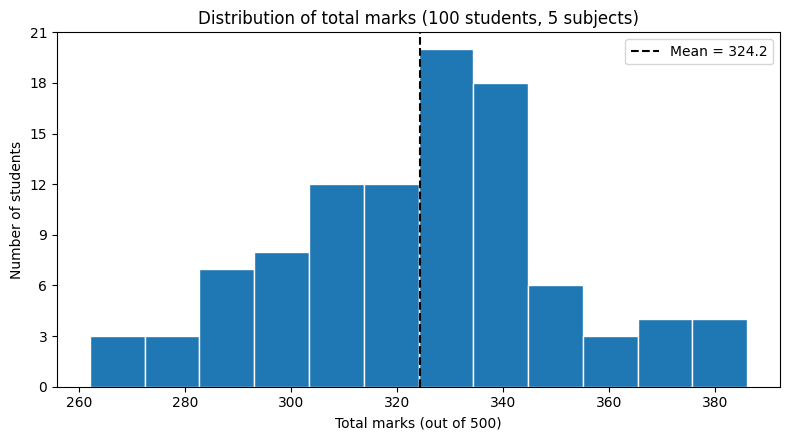

In [234]:
import os
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

os.makedirs("images", exist_ok=True)

# Chart 1: histogram of total marks
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(total_by_student, bins=12, edgecolor="white")
ax.axvline(total_by_student.mean(), color="black", linestyle="--",
           label=f"Mean = {total_by_student.mean():.1f}")
ax.set_title("Distribution of total marks (100 students, 5 subjects)")
ax.set_xlabel("Total marks (out of 500)")
ax.set_ylabel("Number of students")
ax.yaxis.set_major_locator(MaxNLocator(integer=True))   # counts must be whole numbers
ax.legend()
fig.tight_layout()
fig.savefig("images/total_marks_histogram.png", dpi=150)
plt.show()

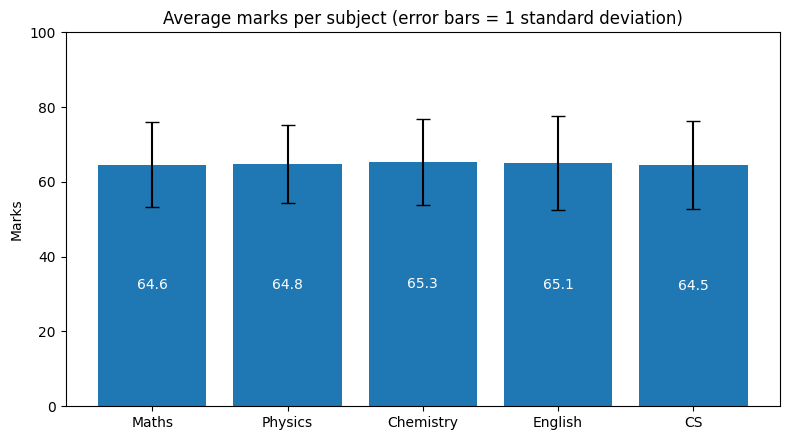

In [235]:
# Chart 2: average per subject, with the standard deviation as error bars
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(SUBJECTS, avg_by_subject, yerr=std_by_subject, capsize=5)
ax.bar_label(bars, labels=[f"{v:.1f}" for v in avg_by_subject], label_type="center", color="white")
ax.set_ylim(0, 100)
ax.set_title("Average marks per subject (error bars = 1 standard deviation)")
ax.set_ylabel("Marks")
fig.tight_layout()
fig.savefig("images/subject_averages.png", dpi=150)
plt.show()

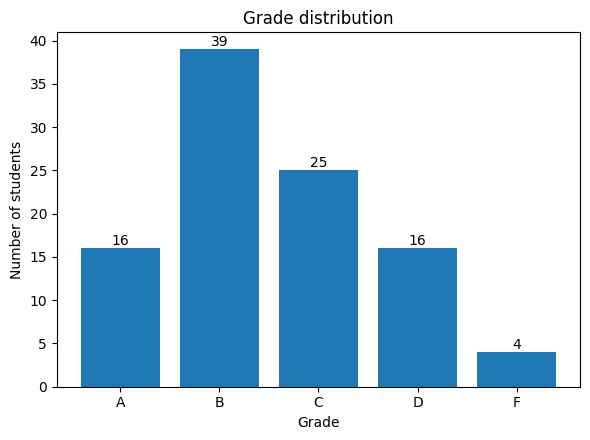

In [236]:
# Chart 3: grade distribution
grade_order = ["A", "B", "C", "D", "F"]
grade_counts = [(grades == g).sum() for g in grade_order]

fig, ax = plt.subplots(figsize=(6, 4.5))
bars = ax.bar(grade_order, grade_counts)
ax.bar_label(bars)
ax.set_title("Grade distribution")
ax.set_xlabel("Grade")
ax.set_ylabel("Number of students")
fig.tight_layout()
fig.savefig("images/grade_distribution.png", dpi=150)
plt.show()

**Reading the charts:**
- The histogram of totals has a single peak just above the mean (about 324). Its shape is a little uneven because there are only 100 students; a larger sample would look smoother.
- The subject averages are almost identical (all within about 1 mark of each other), and the error bars overlap heavily. The differences I found in Stage 2 (Chemistry highest, CS lowest) are **noise**: every subject was generated from the same distribution, so no real difference exists. An honest analyst says that instead of inventing a story.
- The y-axis of the bar chart starts at 0 on purpose. Truncating it would make a 0.8-mark difference look dramatic.

## Key findings

- **Dataset:** 100 students x 5 subjects, overall mean 64.85, mean total 324.24 (median 327).
- **Subjects:** Chemistry has the highest average (65.28) and CS the lowest (64.51). English varies the most (std 12.63), Physics the least (std 10.43). The averages differ by under 1 mark, so this is noise on synthetic data.
- **Topper:** Student 28 with 386 marks. The top 5 are Students 28, 63, 65, 91, 84 (totals 386, 380, 377, 376, 371).
- **Failures:** 1 student failed a subject (Student 59, English, 34 marks, pass mark 35).
- **High scorers:** 8 students scored above 90 in at least one subject (8 scores in total); CS has the most (3).
- **Grace marks:** adding 5 to CS (the weakest subject) raised its average from 64.51 to 69.45, with 2 students capped at 100.
- **Grades:** A: 16, B: 39, C: 25, D: 16, F: 4. Averaging five subjects shrinks the spread, so grade bands must fit the data.

## Summary of learnings

**Random data**
- `np.random.default_rng(seed)` makes random data reproducible; `loc` = mean, `scale` = standard deviation.

**Types and rounding**
- `astype(int)` **truncates toward zero**, so round first.
- NumPy rounds exact `.5` values to the **nearest even** number.
- Pipeline order **clip -> round -> int** is correct for any bounds.

**Axes and booleans**
- `axis=0` gives one value **per column**, `axis=1` one value **per row**. Check `.shape` to confirm.
- `.any(axis=1)` / `.all(axis=1)` collapse a boolean mask to one answer per row; `.sum()` counts Trues; `np.flatnonzero` and `np.argwhere` turn Trues into positions.
- Counting students and counting scores are different questions with different `axis` choices.

**Ranking**
- `argmax`/`argsort` return **indices**, not values. Reverse with `[::-1]`.
- Double `argsort` gives ranks; `searchsorted` gives tie-safe percentile ranks.
- `np.digitize` / `np.select` replace long if/else chains for grading.

**Broadcasting**
- Shapes align from the right; a dimension of 1 stretches. Use `keepdims=True` for per-row statistics.
- `.copy()` before modifying; never rely on `b = a` to copy.

**Habits**
- Predict the shape first, test on a tiny array, verify with a second route.
- Decide boundary rules (`<` vs `<=`) on purpose and write them down.
- Don't invent a story from noise; say when differences are tiny.